In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Load the cleaned modeling dataset
data_path = Path("../data/processed/rossmann_modeling.csv")

df = pd.read_csv(
    data_path,
    parse_dates=["Date"],
    low_memory=False
)

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

display(df.head())


Dataset shape: (844338, 23)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDistanceMissing,Year,Month,Day,WeekOfYear
0,85,2,2013-01-01,4220,619,1,0,a,1,b,...,2011.0,0,NaN,NaN,NaN,0,2013,1,1,1
1,259,2,2013-01-01,6851,1444,1,0,a,1,b,...,NaN,0,NaN,NaN,NaN,0,2013,1,1,1
2,262,2,2013-01-01,17267,2875,1,0,a,1,b,...,2013.0,0,NaN,NaN,NaN,0,2013,1,1,1
3,274,2,2013-01-01,3102,729,1,0,a,1,b,...,NaN,1,10.0,2013.0,"Jan,Apr,Jul,Oct",0,2013,1,1,1
4,335,2,2013-01-01,2401,482,1,0,a,1,b,...,NaN,1,31.0,2013.0,"Jan,Apr,Jul,Oct",0,2013,1,1,1


In [2]:
# Create a copy of the dataset
model_data = df.copy()

# Extract date information
model_data["Month"] = model_data["Date"].dt.month
model_data["Day"] = model_data["Date"].dt.day

# Select input features
features = [
    "Store",
    "DayOfWeek",
    "Month",
    "Day",
    "Promo",
    "SchoolHoliday",
    "StoreType"
]

# Target variable
target = "Sales"

# Display selected features
print("Selected features:", features)
print("Target:", target)

display(model_data[features + [target]].head())


Selected features: ['Store', 'DayOfWeek', 'Month', 'Day', 'Promo', 'SchoolHoliday', 'StoreType']
Target: Sales


,Store,DayOfWeek,Month,Day,Promo,SchoolHoliday,StoreType,Sales
0,85,2,1,1,0,1,b,4220
1,259,2,1,1,0,1,b,6851
2,262,2,1,1,0,1,b,17267
3,274,2,1,1,0,1,b,3102
4,335,2,1,1,0,1,b,2401


In [3]:
# Convert StoreType into numerical columns
model_data = pd.get_dummies(
    model_data,
    columns=["StoreType"],
    dtype=int
)

# Update our feature list
features = [
    "Store",
    "DayOfWeek",
    "Month",
    "Day",
    "Promo",
    "SchoolHoliday",
    "StoreType_a",
    "StoreType_b",
    "StoreType_c",
    "StoreType_d"
]

# Split chronologically (same dates as Week 5)
train_data = model_data[model_data["Date"] < "2015-06-01"]
test_data = model_data[model_data["Date"] >= "2015-06-01"]

# Prepare inputs (X) and target (y)
X_train = train_data[features]
y_train = train_data["Sales"]

X_test = test_data[features]
y_test = test_data["Sales"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", len(features))

display(X_train.head())


Training records: 785727
Testing records: 58611
Number of features: 10


,Store,DayOfWeek,Month,Day,Promo,SchoolHoliday,StoreType_a,StoreType_b,StoreType_c,StoreType_d
0,85,2,1,1,0,1,0,1,0,0
1,259,2,1,1,0,1,0,1,0,0
2,262,2,1,1,0,1,0,1,0,0
3,274,2,1,1,0,1,0,1,0,0
4,335,2,1,1,0,1,0,1,0,0


In [4]:
from sklearn.tree import DecisionTreeRegressor

# Create the Decision Tree model
decision_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=20,
    random_state=42
)

# Train the model
decision_tree.fit(X_train, y_train)

print("Decision Tree trained successfully!")
print("Tree depth:", decision_tree.get_depth())
print("Number of leaves:", decision_tree.get_n_leaves())


Decision Tree trained successfully!
Tree depth: 10
Number of leaves: 612


In [5]:
# Generate predictions using the Decision Tree
tree_predictions = decision_tree.predict(X_test)

# Compare actual and predicted sales
results = test_data[["Date", "Store", "Sales"]].copy()

results["PredictedSales"] = tree_predictions.round(2)

# Display the first 10 predictions
display(results.head(10))


,Date,Store,Sales,PredictedSales
785727,2015-06-01,1,5774,9491.98
785728,2015-06-01,2,6629,9504.83
785729,2015-06-01,3,11594,9504.83
785730,2015-06-01,4,13727,9491.98
785731,2015-06-01,5,8396,9504.83
785732,2015-06-01,6,7054,9504.83
785733,2015-06-01,7,14160,9504.83
785734,2015-06-01,8,10971,9504.83
785735,2015-06-01,9,12227,9504.83
785736,2015-06-01,10,7846,9504.83


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Actual and predicted sales
actual = y_test
predicted = tree_predictions

# Calculate evaluation metrics
tree_mae = mean_absolute_error(actual, predicted)
tree_rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Decision Tree Model Evaluation")
print(f"MAE: {tree_mae:.2f}")
print(f"RMSE: {tree_rmse:.2f}")

# Compare with Week 5 baseline
baseline_mae = 2199.64
baseline_rmse = 3009.76

print("\nBaseline vs Decision Tree")
print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Decision Tree MAE: {tree_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Decision Tree RMSE: {tree_rmse:.2f}")

Decision Tree Model Evaluation
MAE: 1880.80
RMSE: 2622.34

Baseline vs Decision Tree
Baseline MAE: 2199.64
Decision Tree MAE: 1880.80
Baseline RMSE: 3009.76
Decision Tree RMSE: 2622.34


In [7]:
import joblib
import os

# Create a folder for saved models
os.makedirs("models", exist_ok=True)

# Save the trained Decision Tree
joblib.dump(decision_tree, "models/decision_tree.pkl")

# Save the feature names and their order
joblib.dump(
    X_train.columns.tolist(),
    "models/features.pkl"
)

print("Decision Tree model saved successfully!")
print("Number of features:", len(X_train.columns))
print("Saved files:")
print("- models/decision_tree.pkl")
print("- models/features.pkl")


Decision Tree model saved successfully!
Number of features: 10
Saved files:
- models/decision_tree.pkl
- models/features.pkl


In [8]:
import joblib
import pandas as pd

# Load the saved model and feature names
model = joblib.load("models/decision_tree.pkl")
feature_names = joblib.load("models/features.pkl")

def predict_sales(store, day_of_week, month, day,
                  promo, school_holiday, store_type):

    # Prepare user input
    input_data = {
        "Store": store,
        "DayOfWeek": day_of_week,
        "Month": month,
        "Day": day,
        "Promo": promo,
        "SchoolHoliday": school_holiday,
        "StoreType_a": int(store_type == "a"),
        "StoreType_b": int(store_type == "b"),
        "StoreType_c": int(store_type == "c"),
        "StoreType_d": int(store_type == "d")
    }

    # Convert input into a DataFrame
    input_df = pd.DataFrame([input_data])

    # Ensure the same feature order as training
    input_df = input_df[feature_names]

    # Generate prediction
    prediction = model.predict(input_df)[0]

    return round(max(0, prediction), 2)

print("Prediction function created successfully!")

Prediction function created successfully!


In [9]:
# Example store information
store = 1
day_of_week = 1       # Monday
month = 6             # June
day = 1
promo = 1             # Promotion active
school_holiday = 0    # No school holiday
store_type = "c"

# Generate sales prediction
predicted_sales = predict_sales(
    store,
    day_of_week,
    month,
    day,
    promo,
    school_holiday,
    store_type
)

print("BizInsight - Sales Prediction")
print("-----------------------------")
print("Store:", store)
print("Date: 2015-06-01")
print("Promotion:", "Yes" if promo == 1 else "No")
print("Store Type:", store_type)
print(f"Predicted Daily Sales: {predicted_sales:,.2f}")


BizInsight - Sales Prediction
-----------------------------
Store: 1
Date: 2015-06-01
Promotion: Yes
Store Type: c
Predicted Daily Sales: 9,491.98


In [10]:
%pip install ipywidgets


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [20]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from datetime import date

# Input fields
store_input = widgets.IntText(value=1, description="Store:")

date_input = widgets.DatePicker(
    description="Date:",
    value=date(2015, 6, 1)
)

promo_input = widgets.Dropdown(
    options=[("No", 0), ("Yes", 1)],
    value=1,
    description="Promotion:"
)

holiday_input = widgets.Dropdown(
    options=[("No", 0), ("Yes", 1)],
    value=0,
    description="School Holiday:"
)

store_type_input = widgets.Dropdown(
    options=["a", "b", "c", "d"],
    value="c",
    description="Store Type:"
)

# Prediction button
predict_button = widgets.Button(
    description="Predict Sales",
    button_style="success"
)

output = widgets.Output()

def on_predict_clicked(button):
    with output:
        clear_output()

        selected_date = date_input.value

        if selected_date is None:
            print("Error: Please select a valid date.")
            return

        if not 1 <= store_input.value <= 1115:
            print("Error: Store ID must be between 1 and 1115.")
            return
            
        try:
            prediction = predict_sales(
                store=store_input.value,
                day_of_week=selected_date.isoweekday(),
                month=selected_date.month,
                day=selected_date.day,
                promo=promo_input.value,
                school_holiday=holiday_input.value,
                store_type=store_type_input.value
    )
        except Exception as e:
            print(f"Prediction failed: {e}")
            return
        

        print("BizInsight - Sales Prediction")
        print("-----------------------------")
        print("Store:", store_input.value)
        print("Date:", selected_date)
        print(f"Predicted Daily Sales: {prediction:,.2f}")

predict_button.on_click(on_predict_clicked)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>BizInsight - Sales Forecast</h3>"),
    store_input,
    date_input,
    promo_input,
    holiday_input,
    store_type_input,
    predict_button,
    output
]))


In [15]:
# Temporarily simulate a prediction failure
original_predict_sales = predict_sales

def predict_sales(*args, **kwargs):
    raise RuntimeError("Simulated model prediction failure")

In [18]:
predict_sales = original_predict_sales

print("Original prediction function restored successfully!")

Original prediction function restored successfully!


In [12]:
# Week 7 - Step 5: Test the prediction workflow

test_cases = [
    {
        "store": 1,
        "day_of_week": 1,
        "month": 6,
        "day": 1,
        "promo": 1,
        "school_holiday": 0,
        "store_type": "c"
    },
    {
        "store": 2,
        "day_of_week": 2,
        "month": 6,
        "day": 2,
        "promo": 0,
        "school_holiday": 0,
        "store_type": "a"
    },
    {
        "store": 3,
        "day_of_week": 3,
        "month": 6,
        "day": 3,
        "promo": 1,
        "school_holiday": 0,
        "store_type": "a"
    }
]

print("BizInsight - Prediction Workflow Tests")
print("--------------------------------------")

for i, case in enumerate(test_cases, start=1):
    prediction = predict_sales(**case)

    print(f"\nTest {i}")
    print(f"Store: {case['store']}")
    print(f"Promotion: {case['promo']}")
    print(f"Predicted Sales: {prediction:,.2f}")

    assert prediction >= 0
    print("Status: PASSED")


BizInsight - Prediction Workflow Tests
--------------------------------------

Test 1
Store: 1
Promotion: 1
Predicted Sales: 9,491.98
Status: PASSED

Test 2
Store: 2
Promotion: 0
Predicted Sales: 6,087.85
Status: PASSED

Test 3
Store: 3
Promotion: 1
Predicted Sales: 7,371.31
Status: PASSED


In [26]:
# Temporarily simulate a model failure
original_predict_sales = predict_sales

def predict_sales(*args, **kwargs):
    raise RuntimeError("Simulated model prediction failure")

In [27]:
predict_sales = original_predict_sales

print("Original prediction function restored successfully!")

Original prediction function restored successfully!


## Week 4 — Model Performance Evaluation

In [28]:
import pandas as pd

results = pd.DataFrame({
    "Metric": ["MAE", "RMSE"],
    "Baseline": [2199.64, 3009.76],
    "Decision Tree": [1880.80, 2622.34]
})

results["Improvement (%)"] = (
    (results["Baseline"] - results["Decision Tree"])
    / results["Baseline"] * 100
).round(2)

display(results)

,Metric,Baseline,Decision Tree,Improvement (%)
0,MAE,2199.64,1880.80,14.50
1,RMSE,3009.76,2622.34,12.87


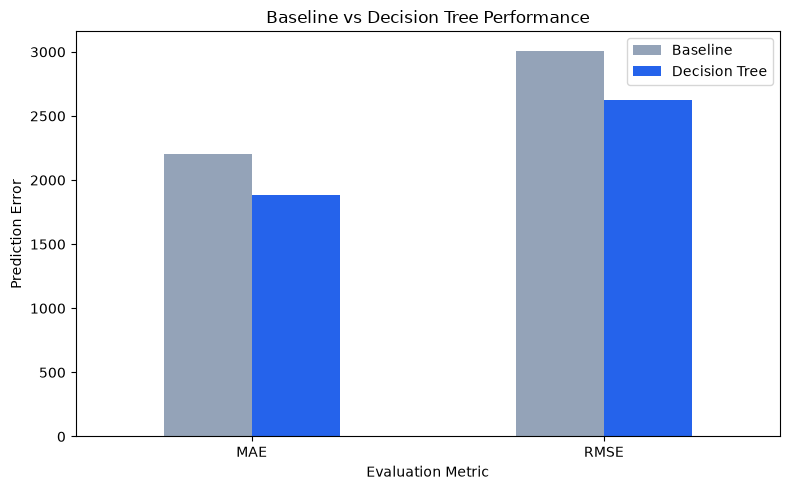

In [29]:
import matplotlib.pyplot as plt

results.set_index("Metric")[
    ["Baseline", "Decision Tree"]
].plot(
    kind="bar",
    figsize=(8, 5),
    color=["#94A3B8", "#2563EB"],
    rot=0
)

plt.title("Baseline vs Decision Tree Performance")
plt.ylabel("Prediction Error")
plt.xlabel("Evaluation Metric")
plt.legend()
plt.tight_layout()
plt.show()

## Practical Model Evaluation and Error Analysis

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Number of test records: {len(y_test)}")
print(f"Decision Tree MAE: {mae:.2f}")
print(f"Decision Tree RMSE: {rmse:.2f}")

Number of test records: 58611
Decision Tree MAE: 1880.80
Decision Tree RMSE: 2622.34


In [31]:
comparison = pd.DataFrame({
    "Actual Sales": np.asarray(y_test),
    "Predicted Sales": predictions
})

comparison["Absolute Error"] = abs(
    comparison["Actual Sales"] -
    comparison["Predicted Sales"]
)

display(comparison.head(10).round(2))

,Actual Sales,Predicted Sales,Absolute Error
0,5774,9491.98,3717.98
1,6629,9504.83,2875.83
2,11594,9504.83,2089.17
3,13727,9491.98,4235.02
4,8396,9504.83,1108.83
5,7054,9504.83,2450.83
6,14160,9504.83,4655.17
7,10971,9504.83,1466.17
8,12227,9504.83,2722.17
9,7846,9504.83,1658.83


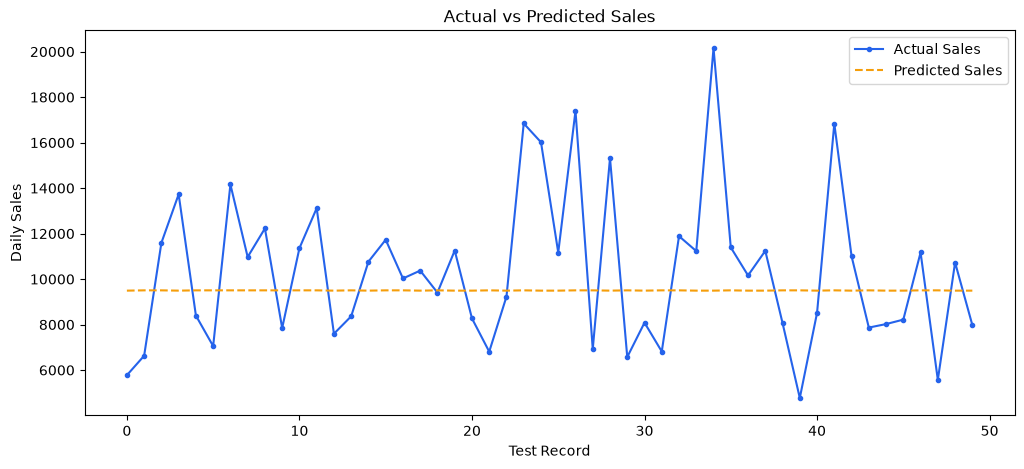

In [32]:
plt.figure(figsize=(12, 5))

plt.plot(
    comparison["Actual Sales"].head(50),
    label="Actual Sales",
    color="#2563EB",
    marker="o",
    markersize=3
)

plt.plot(
    comparison["Predicted Sales"].head(50),
    label="Predicted Sales",
    color="#F59E0B",
    linestyle="--"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Test Record")
plt.ylabel("Daily Sales")
plt.legend()

### Largest Prediction Errors

In [33]:
largest_errors = comparison.nlargest(
    10, "Absolute Error"
)

display(largest_errors.round(2))

print(
    f"Maximum absolute error: "
    f"{comparison['Absolute Error'].max():.2f}"
)

print(
    f"Median absolute error: "
    f"{comparison['Absolute Error'].median():.2f}"
)

,Actual Sales,Predicted Sales,Absolute Error
20382,41551,5576.52,35974.48
21496,30038,5576.52,24461.48
4617,29148,7371.31,21776.69
33788,27330,5576.52,21753.48
28063,29007,7795.76,21211.24
26484,29161,8964.36,20196.64
26443,28664,8964.36,19699.64
3045,26953,7371.31,19581.69
816,29475,9917.13,19557.87
28124,27140,7795.76,19344.24


Maximum absolute error: 35974.48
Median absolute error: 1438.52


### Evaluation of Sales Edge Cases

In [34]:
low_threshold = comparison["Actual Sales"].quantile(0.10)
high_threshold = comparison["Actual Sales"].quantile(0.90)

comparison["Sales Category"] = np.select(
    [
        comparison["Actual Sales"] <= low_threshold,
        comparison["Actual Sales"] >= high_threshold
    ],
    ["Low Sales", "High Sales"],
    default="Normal Sales"
)

edge_case_results = comparison.groupby(
    "Sales Category"
).agg(
    Records=("Actual Sales", "count"),
    Average_Actual=("Actual Sales", "mean"),
    Average_Predicted=("Predicted Sales", "mean"),
    MAE=("Absolute Error", "mean")
)

display(edge_case_results.round(2))

print(f"Low sales threshold: {low_threshold:.2f}")
print(f"High sales threshold: {high_threshold:.2f}")

,Records,Average_Actual,Average_Predicted,MAE
Sales Category,,,,
High Sales,5864,13877.67,8699.89,5232.66
Low Sales,5862,3196.24,5733.99,2543.32
Normal Sales,46885,6816.06,6776.47,1378.75


Low sales threshold: 3949.00
High sales threshold: 11013.00


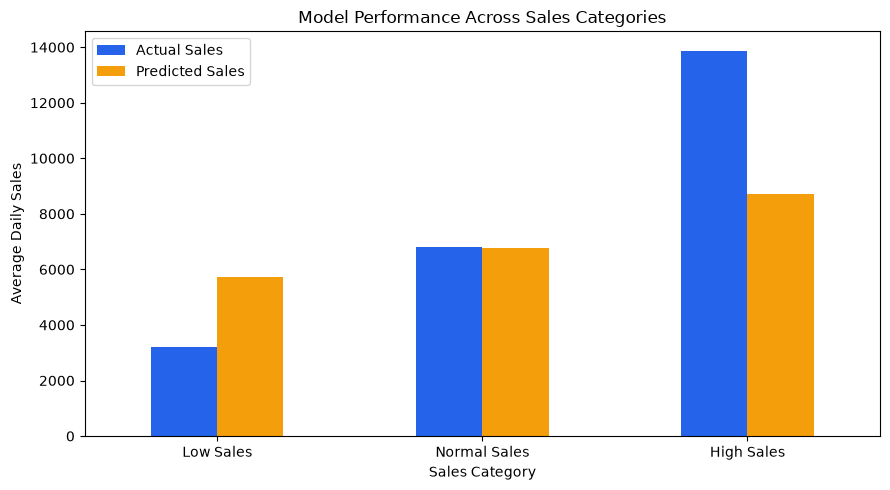

In [35]:
edge_case_results.loc[
    ["Low Sales", "Normal Sales", "High Sales"],
    ["Average_Actual", "Average_Predicted"]
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["#2563EB", "#F59E0B"],
    rot=0
)

plt.title("Model Performance Across Sales Categories")
plt.ylabel("Average Daily Sales")
plt.xlabel("Sales Category")
plt.legend(["Actual Sales", "Predicted Sales"])
plt.tight_layout()
plt.show()